In [140]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [141]:
df = pd.read_csv("/content/diabetes.csv")

In [142]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [143]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [145]:
df.duplicated().sum()

np.int64(0)

In [146]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


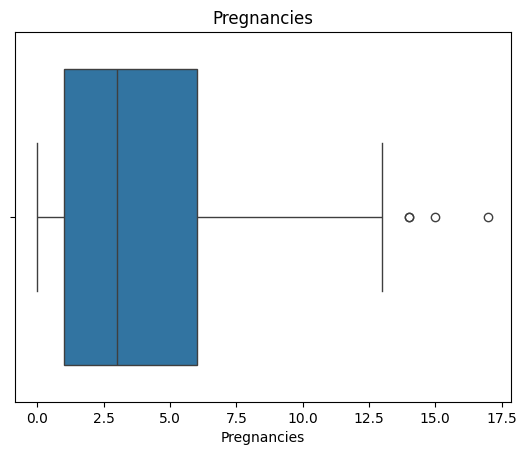

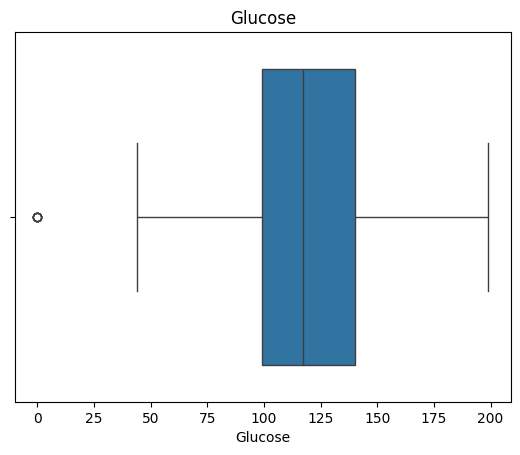

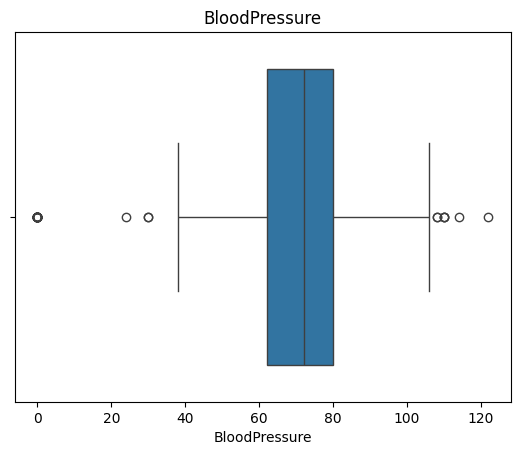

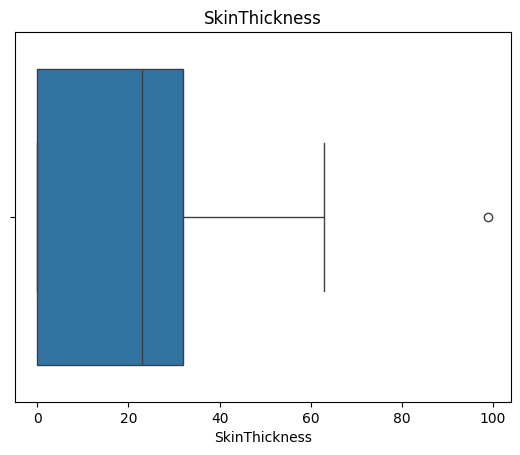

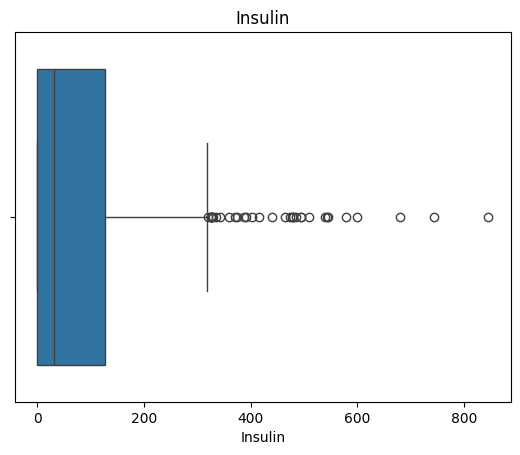

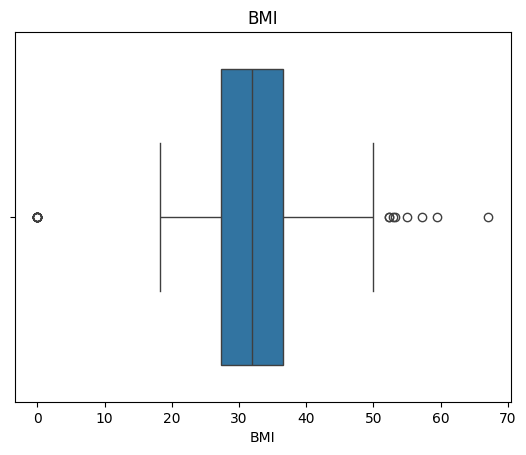

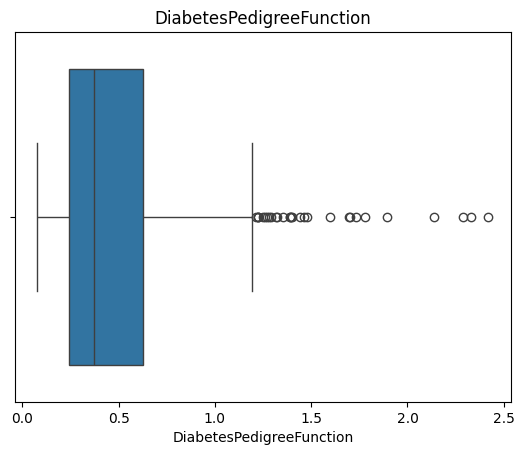

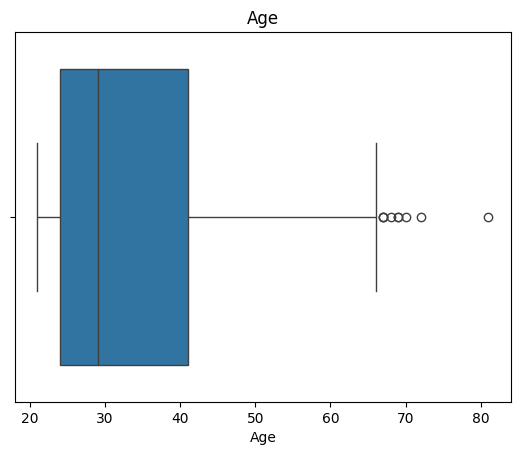

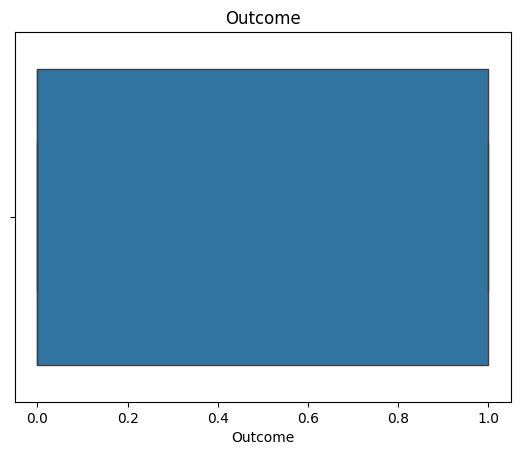

In [147]:
#Outlier
for col in df.select_dtypes(include = 'number').columns:
  sns.boxplot(x = df[col])
  plt.title(col)
  plt.show()

In [148]:
df['Insulin'] = np.log1p(df['Insulin'])

<Axes: xlabel='Insulin'>

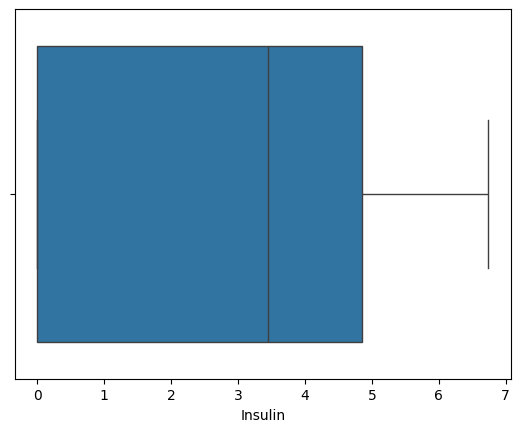

In [149]:
sns.boxplot(x = df['Insulin'])

In [150]:
#Outlier Treatment
df.columns = df.columns.str.strip()

columns = ['Pregnancies', 'Glucose' ,'BloodPressure', 'SkinThickness', 'Insulin', 'Age', 'BMI', 'DiabetesPedigreeFunction']

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

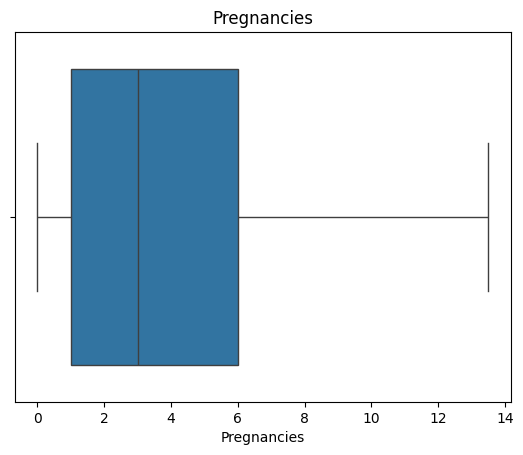

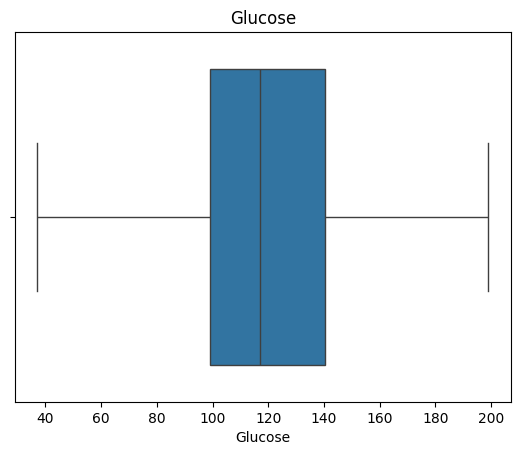

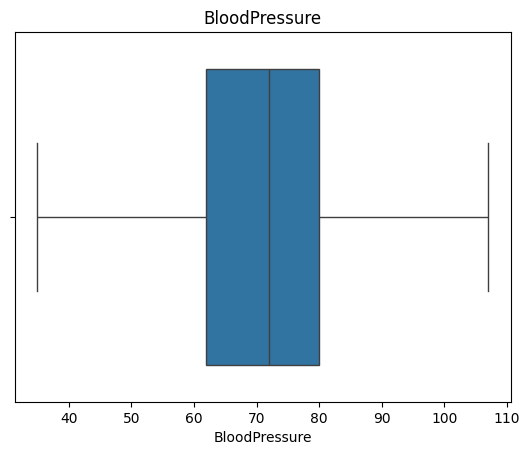

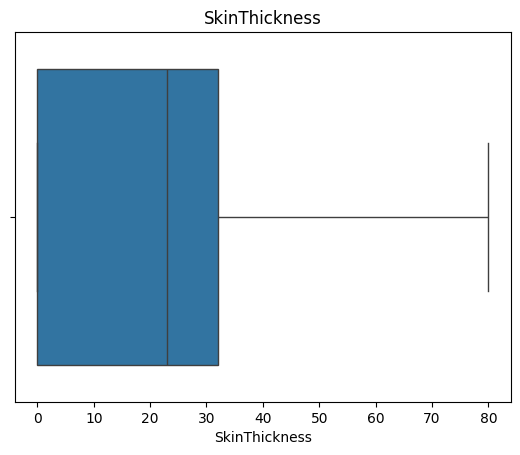

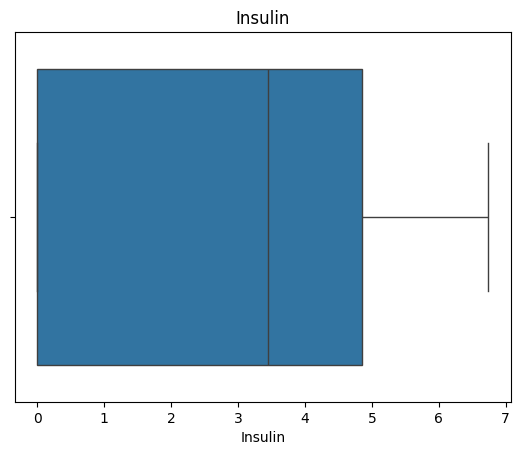

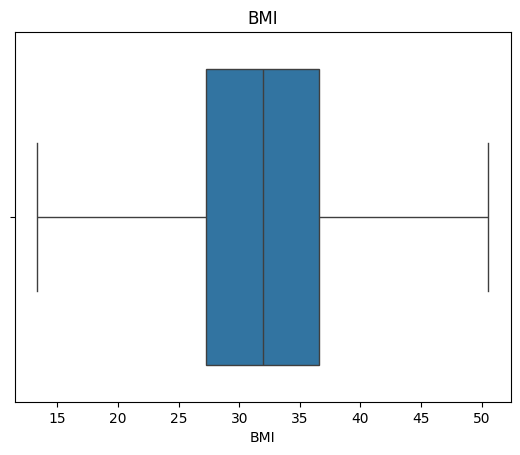

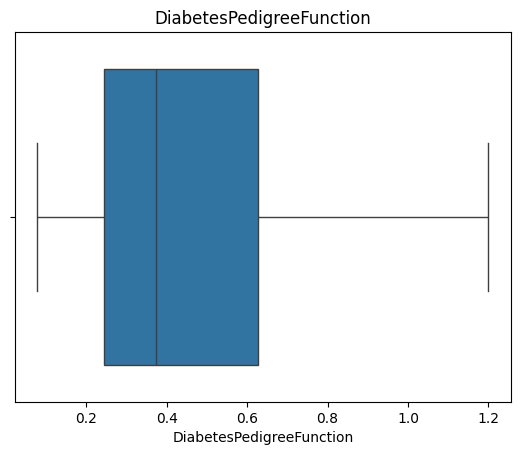

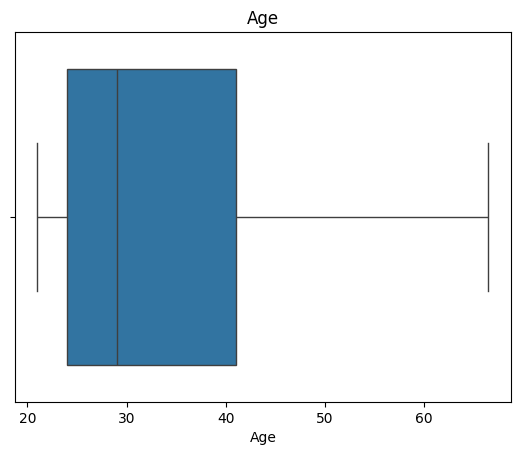

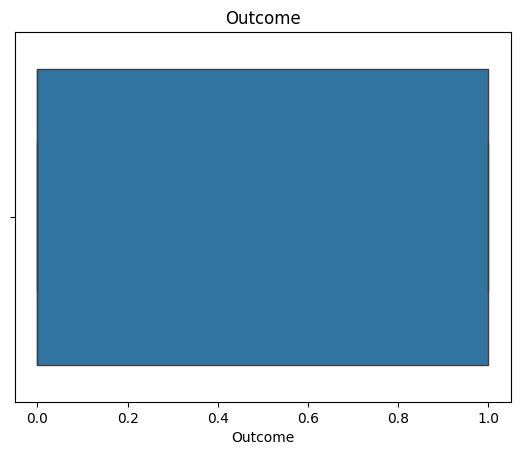

In [151]:
for col in df.select_dtypes(include = 'number').columns:
  sns.boxplot(x = df[col])
  plt.title(col)
  plt.show()

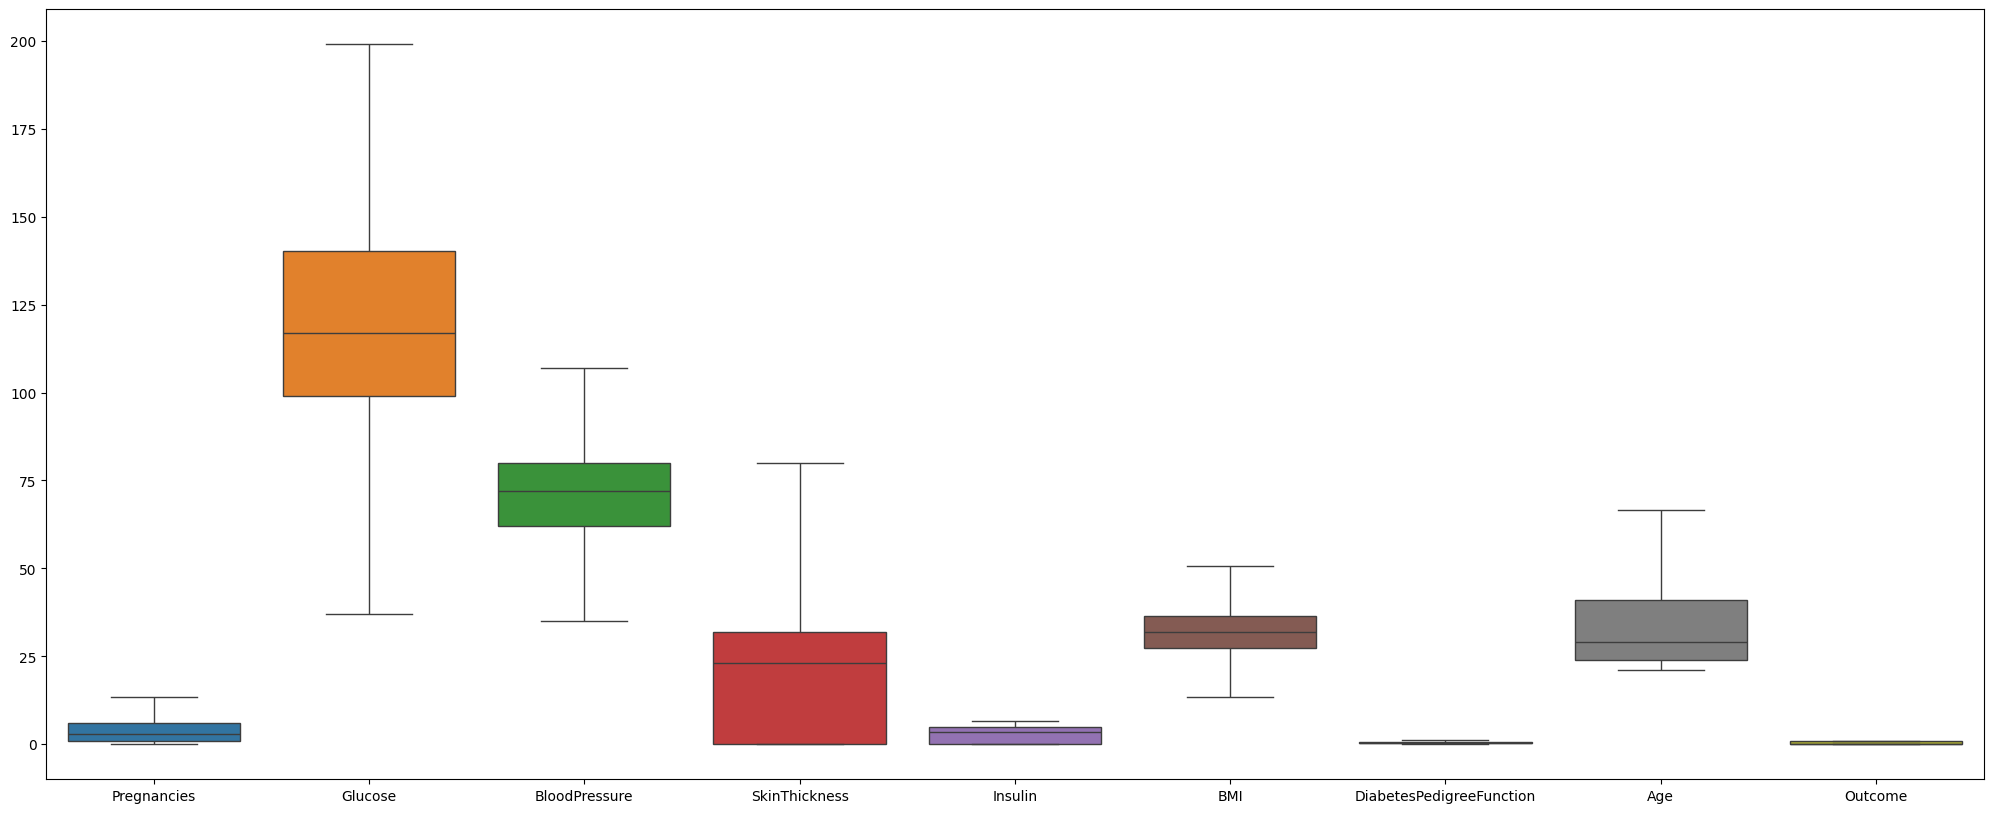

In [152]:
for col in df.select_dtypes(include = 'number').columns:
  if col == "load_id":
    continue
plt.figure(figsize=(25,10))
sns.boxplot(data = df.select_dtypes(include = 'number'))
plt.show()

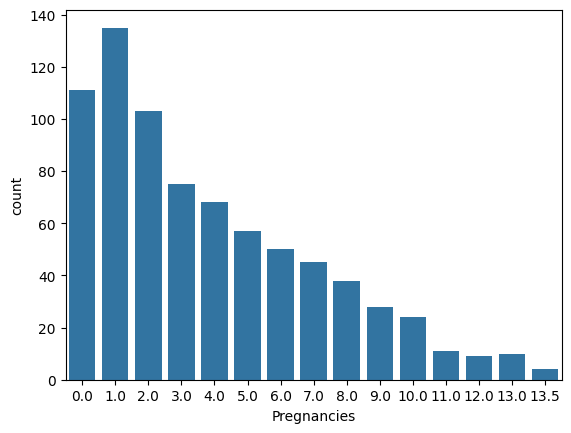

In [153]:
#Univariate Analysis
sns.countplot(x = 'Pregnancies', data = df)
plt.show()

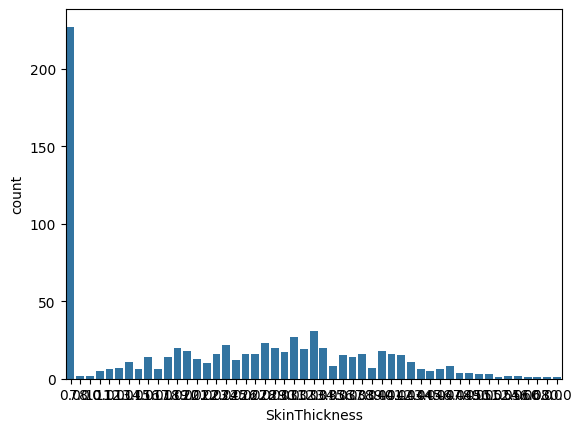

In [154]:
sns.countplot(x = 'SkinThickness', data = df)
plt.show()

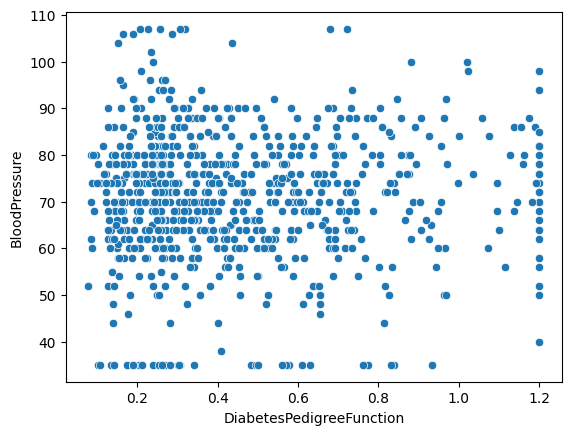

In [155]:
#Bivariated Analysis
sns.scatterplot(x = df['DiabetesPedigreeFunction'], y = df['BloodPressure'])
plt.show()

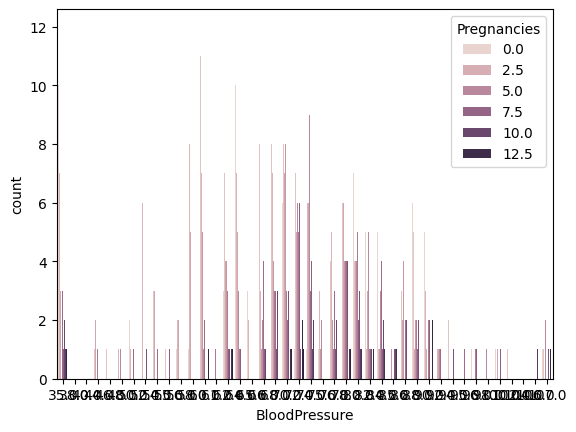

In [156]:
sns.countplot(x = df['BloodPressure'], hue = "Pregnancies", data = df)
plt.show()

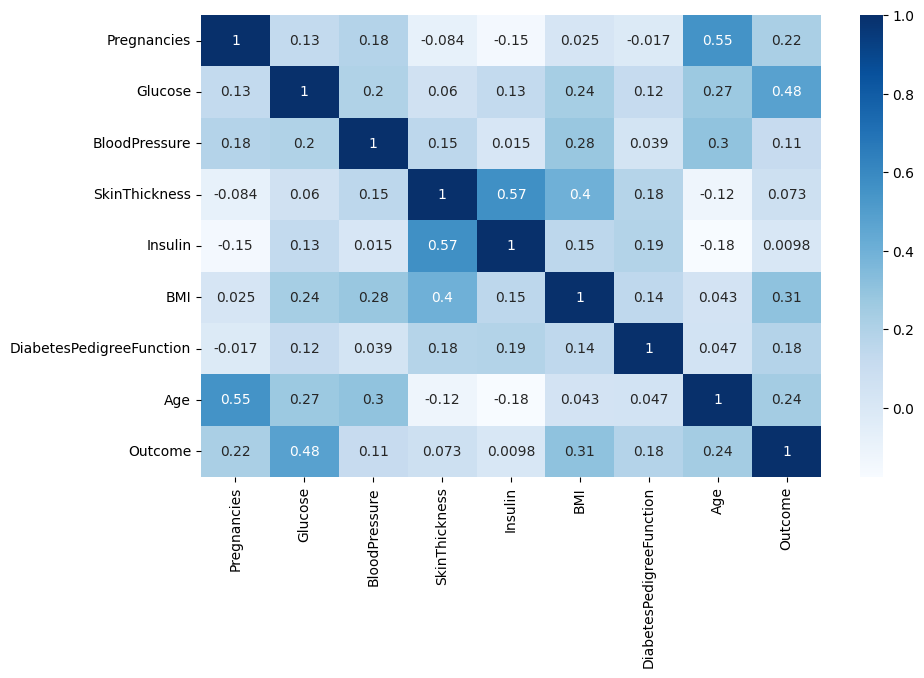

In [157]:
#Multivariated Analysis
plt.figure(figsize = (10,6))
sns.heatmap(df.corr(numeric_only = True), annot = True,  cmap = 'Blues')
plt.show()

In [158]:
#Converting objective to numerical dtype so the machine can understand
df.select_dtypes(include = 'object').columns

Index([], dtype='object')

In [182]:
#Logistic Regression
X = df.drop("Outcome", axis = 1)
y = df["Outcome"]

In [183]:
print(X.shape)
print(y.shape)

(768, 8)
(768,)


In [184]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42, stratify=y)

In [185]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [186]:
y_pred = model.predict(X_test)
print(y_pred)

[1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0
 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 1 0 0 0 1 0]


In [187]:
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7142857142857143


In [188]:
from sklearn.metrics import precision_score
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision:", precision)

Precision: 0.7080525606469003


In [189]:
from sklearn.metrics import f1_score
print("F1 score:", f1_score(y_test, y_pred, average='weighted'))

F1 score: 0.7100432405972097


In [190]:
from sklearn.metrics import recall_score
print("Recall:", recall_score(y_test, y_pred, average='weighted'))

Recall: 0.7142857142857143


In [195]:
from sklearn.metrics import roc_auc_score
print("ROC_AUC:", roc_auc_score(y_test, y_pred, average='weighted', multi_class='ovr'))

ROC_AUC: 0.6735185185185186


In [196]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[81 19]
 [25 29]]


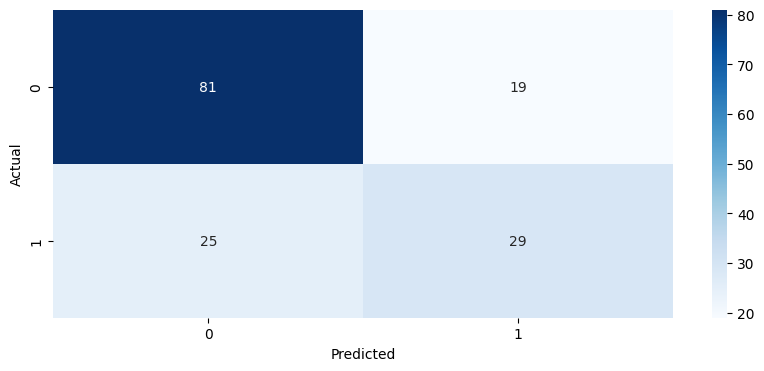

In [199]:
plt.figure(figsize=(10,4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [200]:
print(X.columns)
print("training_accuracy:", model.score(X_train, y_train))
print("testing accuracy:", model.score(X_test, y_test))

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')
training_accuracy: 0.7947882736156352
testing accuracy: 0.7142857142857143
